**SAPIANS** · SCC5819 · MÓDULO 09 — DECOMPOSIÇÃO FUNCIONAL · MOLNAR, CAP. 22

# Separar a superfície exige escolher uma referência

A estatística H resumia um resíduo; agora vamos construir e reconstruir componentes com regras explícitas de centralização.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/09-functional-decomposition/notebooks/decomposition_walkthrough.ipynb)

---

**Objetivos.** Executar o método no modelo fixo do curso, conferir a fórmula e delimitar o que a medida permite concluir.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar()

PosixPath('figures_generated')

## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Escolher a função e a medida de referência

Nossa função é a PD conjunta de idade e saturação: as demais entradas são integradas sobre o fundo. Não é o preditor completo. Discretizamos idade por medianas de grupos de quantis e usamos os pesos marginais do painel. A medida produto é uma referência artificial que rompe a dependência idade–saturação. Sob ela, $f_0=E[f]$, $f_j=E_k[f]-f_0$, $f_k=E_j[f]-f_0$ e $f_{jk}=f-f_0-f_j-f_k$.

In [4]:
print(inspect.getsource(G.decompor_superficie))

# Grade e pesos definidos antes de inspecionar a superfície.
faixas = pd.qcut(painel["idade_anos"], q=8, duplicates="drop")
resumo_idade = painel.groupby(faixas, observed=True)["idade_anos"].agg(
    ["median", "size"]
)
idades = resumo_idade["median"].to_numpy()
wj = resumo_idade["size"].to_numpy(dtype=float)
estados = list(xf["saturacao"].cat.categories)
wk = (
    painel["saturacao"]
    .value_counts()
    .reindex(estados, fill_value=0)
    .to_numpy(dtype=float)
)
pontos = pd.DataFrame(
    itertools.product(idades, estados), columns=["idade_anos", "saturacao"]
)
superficie = G.pd_empirica(prever, xf, pontos).reshape(len(idades), len(estados))
dec = G.decompor_superficie(superficie, wj, wk)
recon_error = np.max(np.abs(superficie - dec["reconstrucao"]))
assert recon_error < 1e-12
assert np.isclose(dec["variancias"].sum(), dec["total"], atol=1e-14)
print(
    "Idades representativas:",
    SP.pt_int(len(idades)),
    "| estados:",
    SP.pt_int(len(estados)),
)
print("Intercepto da superfície:", SP.pt(dec["f0"], 6))
print("Erro máximo de reconstrução:", SP.pt_sig(recon_error, 4))
print("Soma das variâncias:", SP.pt(dec["variancias"].sum(), 10))
print("Variância da superfície sob o produto:", SP.pt(dec["total"], 10))
partes = pd.DataFrame(
    {
        "componente": ["idade", "saturação", "interação"],
        "variância": dec["variancias"],
        "fração no produto": dec["variancias"] / dec["total"],
    }
)
print(SP.tabela(partes, casas=6))
print("Pesos da idade:", ", ".join(SP.pt(v, 4) for v in dec["pesos_j"]))
print("Pesos da saturação:", ", ".join(SP.pt(v, 4) for v in dec["pesos_k"]))

def decompor_superficie(superficie, pesos_j, pesos_k) -> dict:
    """Decomposição ANOVA de uma tabela sob a medida produto declarada.

    A tabela pode ser a PD de um par num modelo maior: nesse caso decompomos
    apenas essa superfície marginalizada, não todas as entradas do preditor.
    Ortogonalidade e parcelas de variância valem sob w_j ⊗ w_k, que não é a
    distribuição conjunta observada de pacientes com entradas dependentes.
    """
    s = np.asarray(superficie, dtype=float)
    wj, wk = np.asarray(pesos_j, float), np.asarray(pesos_k, float)
    if (
        s.ndim != 2
        or wj.ndim != 1
        or wk.ndim != 1
        or s.shape != (len(wj), len(wk))
        or not all(np.isfinite(v).all() for v in (s, wj, wk))
        or (wj < 0).any()
        or (wk < 0).any()
        or wj.sum() <= 0
        or wk.sum() <= 0
    ):
        raise ValueError("Superfície e pesos finitos, não negativos e compatíveis.")
    wj, wk = wj / wj.sum(), wk / wk.sum()
    produto = np.outer(

Idades representativas: 8 | estados: 3
Intercepto da superfície: 0,220314
Erro máximo de reconstrução: 0,0000
Soma das variâncias: 0,0122997211
Variância da superfície sob o produto: 0,0122997211
componente variância fração no produto
     idade  0,010524          0,855655
 saturação  0,001587          0,129004
 interação  0,000189          0,015341
Pesos da idade: 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250
Pesos da saturação: 0,1348, 0,2246, 0,6406


**O que olhar.**

- O erro de reconstrução verifica a identidade na grade, não a fidelidade de uma aproximação ao preditor completo.
- As frações de variância impressas pertencem somente à superfície e à medida produto declarada.

## §3 — Reconstruir com intercepto, efeitos principais e interação

Exibimos a superfície e os componentes na mesma grade. A interação é o que resta após remover intercepto e os efeitos principais definidos pela medida produto.

figura: figures_generated/decomposition-componentes.png


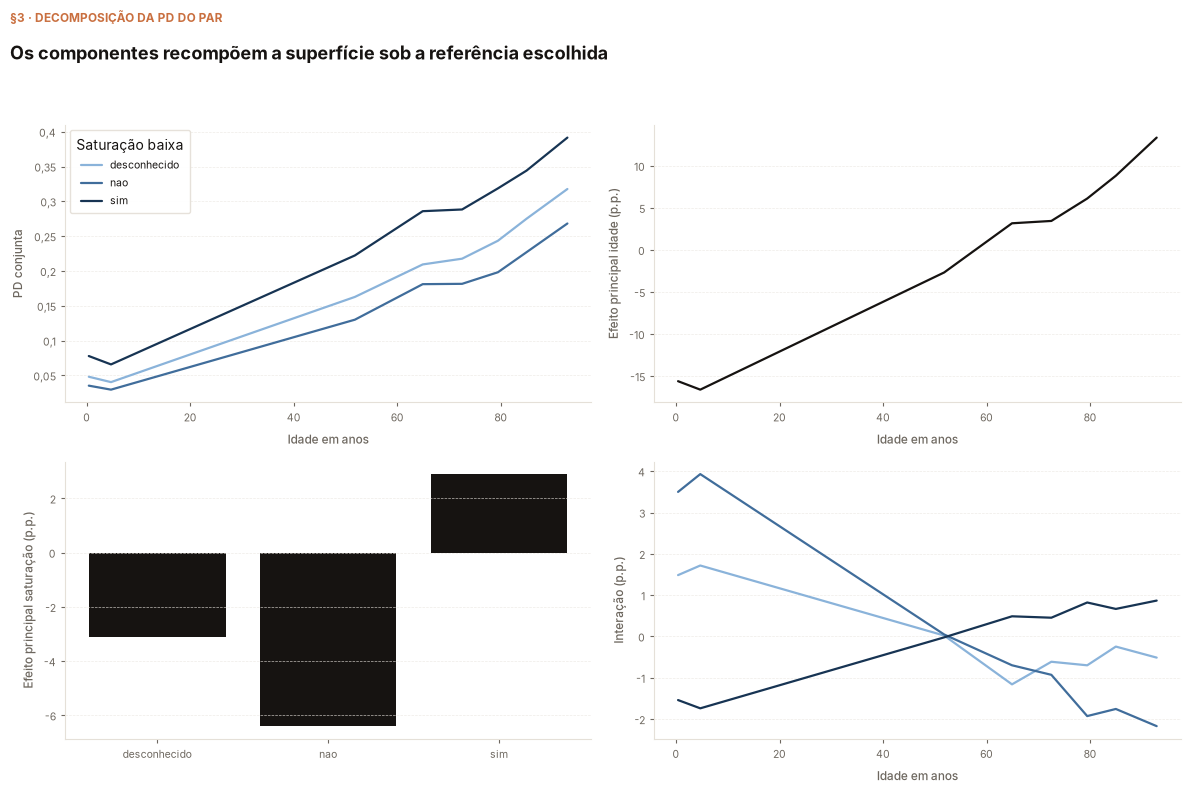

In [5]:
fig, axes = plt.subplots(2, 2, figsize=SP.PAINEL)
for k, estado in enumerate(estados):
    axes[0, 0].plot(
        idades, superficie[:, k], label=estado, color=SP.rampa(len(estados))[k]
    )
    axes[1, 1].plot(
        idades, 100 * dec["fjk"][:, k], label=estado, color=SP.rampa(len(estados))[k]
    )
axes[0, 0].set(ylabel="PD conjunta", xlabel="Idade em anos")
axes[0, 0].legend(title="Saturação baixa")
axes[0, 1].plot(idades, 100 * dec["fj"], color=SP.ESCURO)
axes[0, 1].set(ylabel="Efeito principal idade (p.p.)", xlabel="Idade em anos")
axes[1, 0].bar(estados, 100 * dec["fk"], color=SP.ESCURO)
axes[1, 0].set(ylabel="Efeito principal saturação (p.p.)")
axes[1, 1].set(ylabel="Interação (p.p.)", xlabel="Idade em anos")
SP.titulo(
    fig,
    "Os componentes recompõem a superfície sob a referência escolhida",
    "§3 · Decomposição da PD do par",
)
SP.salvar(fig, "decomposition-componentes")
plt.show()

**O que olhar.**

- O intercepto foi impresso na seção anterior; ele se soma aos componentes centralizados.
- As curvas recompõem valores da grade. A discretização não resolve as previsões entre esses pontos.

## §4 — Mudar a referência redistribui os componentes

Mantemos a superfície, mas atribuímos pesos uniformes aos estados e idades. O intercepto e as parcelas podem mudar, mesmo com reconstrução exata. Isso demonstra por que o condicionamento não é um detalhe.

In [6]:
uniforme = G.decompor_superficie(
    superficie, np.ones(len(idades)), np.ones(len(estados))
)
rows = []
for label, d in [("Produto das marginais", dec), ("Produto uniforme", uniforme)]:
    rows.append(
        {
            "referência": label,
            "intercepto": d["f0"],
            "variância total": d["total"],
            "fração interação": d["variancias"][2] / d["total"],
            "erro reconstrução": np.max(np.abs(d["reconstrucao"] - superficie)),
        }
    )
print(SP.tabela(pd.DataFrame(rows), casas=8))
# Frequências conjuntas reais: diagnóstico de quanto o produto se afasta do painel.
cont = pd.crosstab(faixas, painel["saturacao"], dropna=False).reindex(
    columns=estados, fill_value=0
)
observada = cont.to_numpy() / cont.to_numpy().sum()
produto = np.outer(dec["pesos_j"], dec["pesos_k"])
print(
    "Distância de variação total conjunta vs produto:",
    SP.pt(0.5 * np.abs(observada - produto).sum(), 6),
)
print(
    "Covariância dos efeitos principais na conjunta discretizada:",
    SP.pt(np.sum(observada * dec["fj"][:, None] * dec["fk"][None, :]), 10),
)
print("Não usamos parcelas produto para explicar a variância da coorte observada.")

           referência intercepto variância total fração interação erro reconstrução
Produto das marginais 0,22031385      0,01229972       0,01534107        0,00000000
     Produto uniforme 0,19829438      0,01078857       0,01665946        0,00000000
Distância de variação total conjunta vs produto: 0,072266
Covariância dos efeitos principais na conjunta discretizada: 0,0000639080
Não usamos parcelas produto para explicar a variância da coorte observada.


**O que olhar.**

- A distância impressa compara distribuições discretizadas, sem testar independência populacional.
- A ortogonalidade sob o produto não é transferível automaticamente à distribuição conjunta observada.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/decomposition.html) orienta o mecanismo e a leitura. A decomposição da superfície é exata na grade sob uma medida produto declarada. Ela não reparte automaticamente a variância das previsões dos pacientes. O caso SRAG acrescenta restrições do formulário, seleção hospitalar e deriva temporal. Nenhuma curva é uma estimativa do efeito de tratar ou modificar uma pessoa.

## Fechamento — A medida só faz sentido com seu condicionamento

Identifique preditor, escala, fundo, grade e regra de ponderação antes de interpretar a figura. Uma reconstrução algébrica ou um controle sintético valida o cálculo sob suas hipóteses; não valida as combinações artificiais como pacientes plausíveis.

In [7]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 22](https://christophm.github.io/interpretable-ml-book/decomposition.html). Referências completas e configuração no [README](../README.md).